# イベント選択

再構成ツリーから、イメージングに使う「きれいなコンプトン散乱イベント」を選びます。
条件は本番解析(`s2p_chk_std2_Erica_v2_1.cc` の `SetCrit`)と同じで、`tu.setcrit()` に実装しています。

「エネルギー範囲 → 飛跡が丸ごと検出器内 → ガス中で止まった電子らしい → 1 回のコンプトン散乱として矛盾しない」
の順に絞っていきます。最後に、**カットごとにエネルギースペクトルがどう変わるか**を重ね描きします。

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 再構成データ

DataIO と同じチェーンを先頭 50000 イベントで実行します(`tutorials/cache/` に保存し、他のノートブックと共有します)。
`err_flag == 0`(シングルヒットとして再構成できた)行だけを使います。

In [3]:
OUT = tu.get_reconstructed("Per02", 50000)
ev = tu.load_single_hit(OUT)
cuts, der = tu.setcrit(ev)
Eg, Ke, Len = ev["Eg"], ev["Ke"], ev["Len_TRA"]
E0 = Eg + Ke
TrkMin, TrkMax = ev["Track_Min"], ev["Track_Max"]
print("err_flag == 0:", len(Eg))

Per02_50000.root は既にあるので再実行しません(overwrite=True で作り直し)


err_flag == 0: 26697


## 3. カットの一覧

| 条件 | 内容 | 意味 |
|---|---|---|
| Eg | 0.15 MeV ≤ Eg ≤ 2.1 MeV | シンチの閾値付近のノイズ・低エネルギー背景と、ダイナミックレンジを超えるイベントを除く |
| 有効体積 (criteria[0]) | 飛跡の範囲 `Track_Min/Max` が x, y とも −148.6〜148.6 mm、z が 32〜327 mm | 飛跡**全体**が読み出し領域(±153.6 mm = 384 strip × 0.8 mm / 2)と GEM 面(z = 27 mm)・ドリフト上端から 5 mm 以上内側にある。壁や GEM からはみ出した飛跡は Ke を測り損ね、方向も怪しい。構造物由来の背景も減らす |
| dE/dx (criteria[1]) | `913.9·Ke² + 2.2 < Len < 1975.9·Ke^1.4 + 7`(Ke [MeV], Len [mm])かつ `Len < 270` | 電子の飛程はエネルギーでほぼ決まる。長すぎる = 宇宙線ミューオンなど最小電離粒子や Ke の測り損ね、短すぎる = 陽子・α など dE/dx の大きい粒子や飛跡の取りこぼし。**ガス中で止まった電子**を選ぶ粒子識別 |
| Δcos α (criteria[2]) | −0.5 ≤ cos α_geo − cos α_kin ≤ 0.5 | 反跳電子と散乱ガンマ線のなす角を、飛跡から(幾何)とエネルギーから(運動学)の 2 通りで求めて比べる ETCC 固有のカット。電子の向きの誤判定、散乱点のずれ、偶然同時計数、多重散乱などを除く |

以下、カットを上から順に積み重ねながら、それぞれの分布と境界を見ていきます。

## 4. 各カット

### 4a. Eg

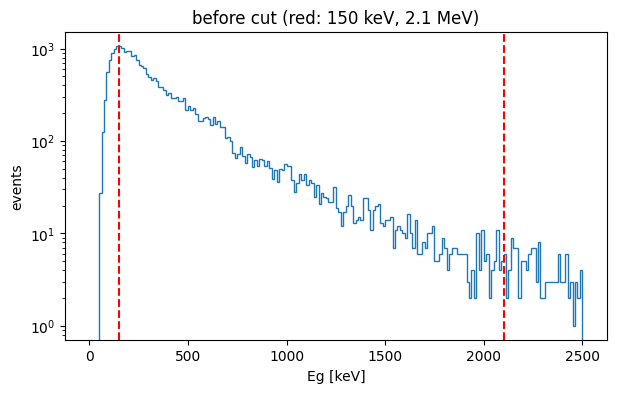

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(Eg, bins=200, range=(0, 2500), histtype="step")
for x in (150, 2100): ax.axvline(x, color="r", ls="--")
ax.set_yscale("log"); ax.set_xlabel("Eg [keV]"); ax.set_ylabel("events"); ax.set_title("before cut (red: 150 keV, 2.1 MeV)")
plt.show()

### 4b. 有効体積

Eg カットを通ったイベントの、飛跡の端点 `Track_Min`, `Track_Max` の分布です。赤線の内側に飛跡全体が入っているものを残します。

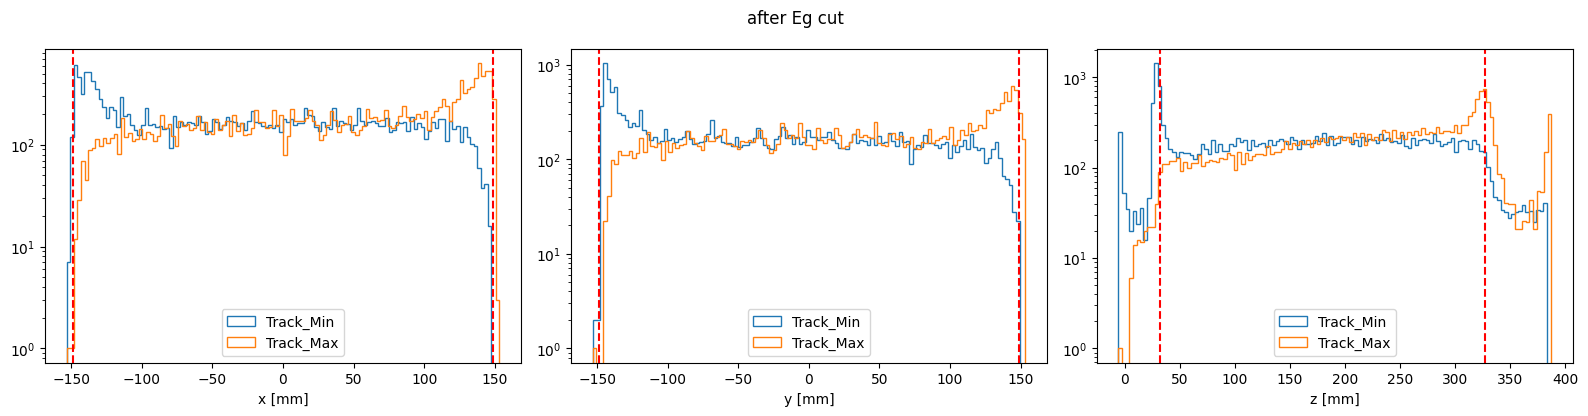

In [5]:
s = cuts["Eg"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k, (lab, lo, hi) in enumerate([("x", -148.6, 148.6), ("y", -148.6, 148.6), ("z", 32.0, 327.0)]):
    ax[k].hist(TrkMin[s, k], bins=120, histtype="step", label="Track_Min")
    ax[k].hist(TrkMax[s, k], bins=120, histtype="step", label="Track_Max")
    for x in (lo, hi): ax[k].axvline(x, color="r", ls="--")
    ax[k].set_xlabel(f"{lab} [mm]"); ax[k].set_yscale("log"); ax[k].legend()
fig.suptitle("after Eg cut"); fig.tight_layout(); plt.show()

### 4c. dE/dx

Eg と有効体積のカットを通ったイベントの、電子のエネルギーと飛程の関係です。2 本の曲線の間(かつ 270 mm 未満)を残します。

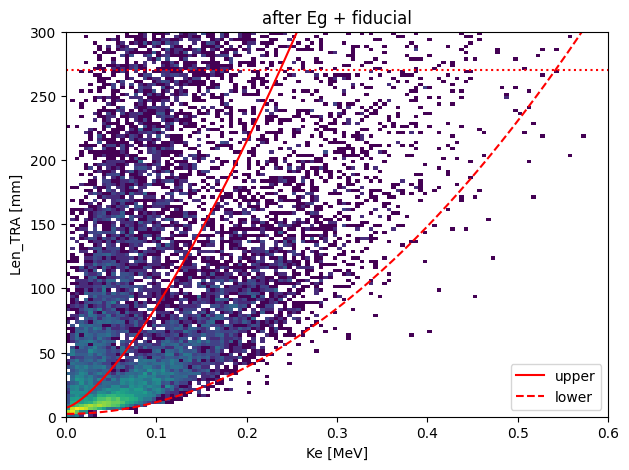

In [6]:
s = cuts["Eg"] & cuts["fiducial"]
ke = np.linspace(0.001, 0.6, 300)
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist2d(Ke[s] / 1000., Len[s], bins=[120, 120], range=[[0, 0.6], [0, 300]], cmin=1, norm="log")
ax.plot(ke, 1975.9 * ke**1.4 + 7., "r-", label="upper")
ax.plot(ke, 913.9 * ke**2.0 + 2.2, "r--", label="lower")
ax.axhline(270, color="r", ls=":")
ax.set_xlabel("Ke [MeV]"); ax.set_ylabel("Len_TRA [mm]"); ax.set_title("after Eg + fiducial"); ax.legend()
plt.show()

### 4d. Δcos α

`cos α_geo = ĝ · ê`(`ĝ = (Pg − Pe)/|Pg − Pe|`、`ê = Ve/|Ve|`)と、`Eg`, `Ke` だけから求めた `cos α_kin` の差です。
正しく再構成できたコンプトン散乱なら 0 の周りに集まります。

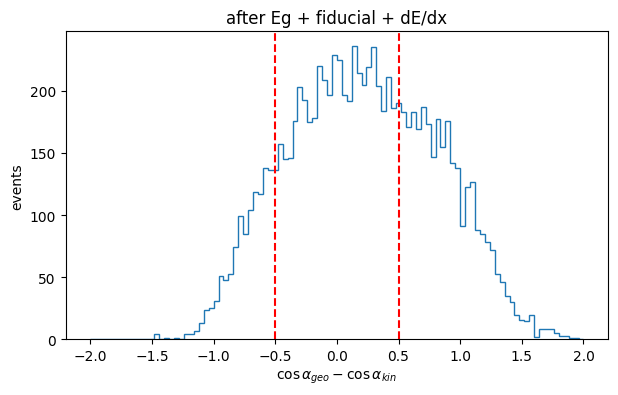

In [7]:
s = cuts["Eg"] & cuts["fiducial"] & cuts["dEdx"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(der["dcos"][s], bins=100, range=(-2, 2), histtype="step")
for x in (-0.5, 0.5): ax.axvline(x, color="r", ls="--")
ax.set_xlabel(r"$\cos\alpha_{geo} - \cos\alpha_{kin}$"); ax.set_ylabel("events"); ax.set_title("after Eg + fiducial + dE/dx")
plt.show()

## 5. カットフロー

In [8]:
steps = [("err_flag == 0", np.ones(len(Eg), bool))]
acc = np.ones(len(Eg), bool)
for name, label in [("Eg", "+ Eg 0.15-2.1 MeV"), ("fiducial", "+ fiducial volume"),
                    ("dEdx", "+ dE/dx"), ("dcos_alpha", "+ |dcos alpha| <= 0.5")]:
    acc = acc & cuts[name]
    steps.append((label, acc.copy()))
n0 = steps[0][1].sum()
for label, m in steps:
    print(f"{label:24s} {m.sum():7d}  {m.sum() / n0:6.1%}")

err_flag == 0              26697  100.0%
+ Eg 0.15-2.1 MeV          21037   78.8%
+ fiducial volume          15234   57.1%
+ dE/dx                     9143   34.2%
+ |dcos alpha| <= 0.5       4887   18.3%


## 6. カットごとのエネルギースペクトル

各段階で残ったイベントのスペクトルを重ね描きします。
左から入射ガンマ線 `E0 = Eg + Ke`、散乱ガンマ線 `Eg`、反跳電子 `Ke` です。
カットを重ねるごとに背景が減り、線源のピークが目立っていく様子が分かります。

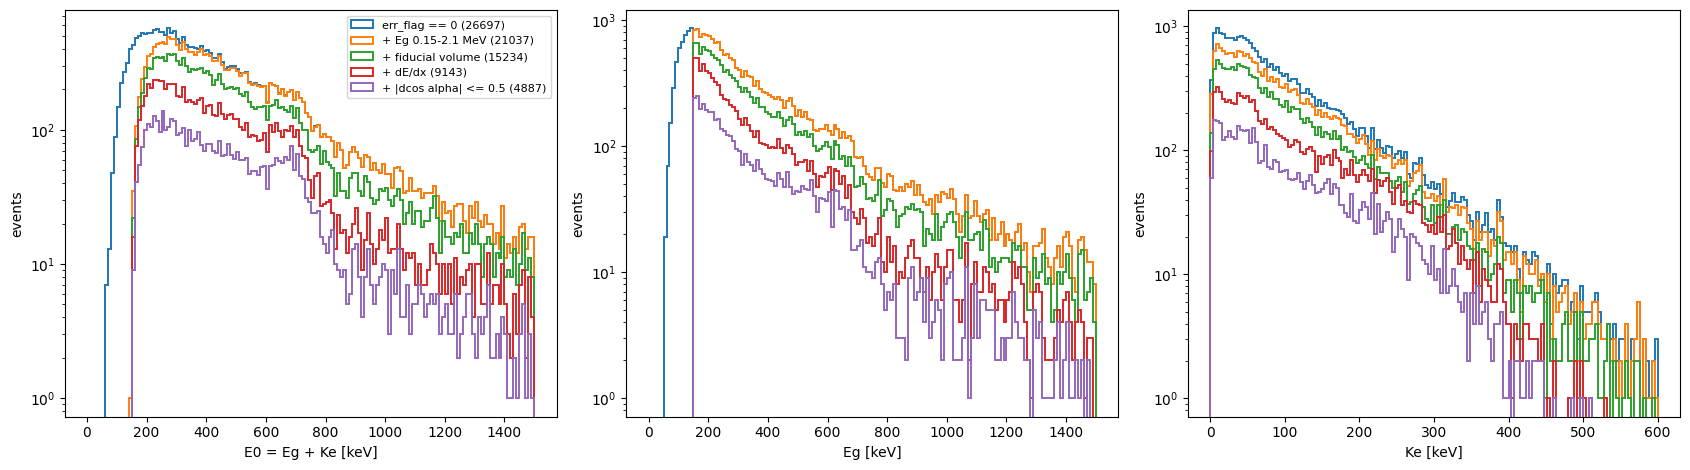

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for (x, rng, lab), a in zip([(E0, (0, 1500), "E0 = Eg + Ke [keV]"),
                             (Eg, (0, 1500), "Eg [keV]"),
                             (Ke, (0, 600), "Ke [keV]")], ax):
    for label, m in steps:
        a.hist(x[m], bins=150, range=rng, histtype="step", lw=1.4, label=f"{label} ({m.sum()})")
    a.set_xlabel(lab); a.set_ylabel("events"); a.set_yscale("log")
ax[0].legend(fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()